# Première inspection d’un dataset

**Projet / problématique commune :** Projet compagnon immo

**Dataset :** base-ic-couples-familles-menages.csv

**Responsable :** … · **Relecteur :** …

**Contributeurs :** Gabrielle RICHERT · **Date :** 16/10/2026

**Version des données :** …

**Référence du fichier / source :** …

## Mode d’emploi collectif

Dupliquer ce notebook pour chaque dataset. Suivre les étapes dans l’ordre et revenir sur une conclusion si une observation ultérieure la remet en cause. Les cellules de code sont vides : vous choisissez les opérations, et pouvez ajouter des cellules.

- Renseigner « non applicable » ou « information inconnue » plutôt que forcer une réponse.
- Conserver les résultats utiles et les figures près de leur commentaire.
- Distinguer observations, hypothèses et décisions ; des points peuvent rester à approfondir.
- Rédiger un seul bilan par grande étape, réutilisable dans le rapport de recherche.
- Faire relire les conclusions par un autre membre du groupe.

**Référence du notebook / script destiné à la remise séparée du code :** …

## Définition IRIS

**IRIS (Îlots Regroupés pour l'Information Statistique)** est l'unité territoriale fondamentale utilisée par l'Insee pour diffuser des données statistiques à une échelle infra-communale.

Ce découpage concerne principalement les communes de plus de 10 000 habitants et la plupart de celles de 5 000 à 10 000 habitants. L'objectif principal est de fournir des zones géographiques homogènes d'environ 2 000 habitants (généralement entre 1 800 et 5 000).

**Types d'IRIS** :

- d'habitat /H, représente environ 92 % des IRIS. Il regroupe une population résidente (entre 1 800 et 5 000 habitants) dans un quartier présentant une homogénéité en matière de logements et de cadre de vie.
- d'activité/A, zone à vocation économique ou industrielle. Il rassemble au moins 1 000 salariés et compte au moins deux fois plus d'emplois salariés que de résidents.
- divers /D, zones spécifiques de grande superficie mais très peu habitées. Il s'agit généralement de forêts, parcs de loisirs, zones portuaires, emprises militaires ou grands espaces naturels (ex. le Parc de la Tête d'Or à Lyon).
- commune non découpée/Z, s'applique aux communes de taille plus modeste dont le territoire n'a pas été divisé en sous-quartiers. La commune entière est alors assimilée à un seul IRIS.

## 1. Situer la source et ouvrir les données

**À faire dans l’ordre :**
1. Identifier la source et consulter la documentation.
2. Préciser la collecte et le périmètre annoncés.
3. Charger les données et vérifier leur lecture.

| Élément | Information | Référence / réserve |
|---|---|---|
| Producteur / origine | INSEE 2022 via l'IRIS | Recensement de la population, base infracommunale 2022 |
| Finalité initiale | Recensement |
| Mode de collecte | Recensement de la population | |
| Extraction / mise à jour | données de 2022 diffusées selon la géographie en vigueur au 1er janvier 2024 |  |
| Documentation / licence | https://www.insee.fr/fr/statistiques/8647008#consulter | |
| Population / objets annoncés | population française recensée en 2022 | |
| Période / territoire, si pertinents | France hors Mayotte, 2022 | |

In [2]:
cd C:\Users\gabi9\Documents\GITHUB_PROJET_LIORA\projet_compagnon\data\base-ic-couples-familles-menages-2022_csv

C:\Users\gabi9\Documents\GITHUB_PROJET_LIORA\projet_compagnon\data\base-ic-couples-familles-menages-2022_csv


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [4]:
menages = pd.read_csv("base-ic-couples-familles-menages-2022.CSV", sep=';')
menages.head(10)

C:\Users\gabi9\AppData\Local\Temp\ipykernel_5196\2463951880.py:1: DtypeWarning: Columns (0: IRIS, 1: COM, 3: LAB_IRIS) have mixed types. Specify dtype option on import or set low_memory=False.
  menages = pd.read_csv("base-ic-couples-familles-menages-2022.CSV", sep=';')


,IRIS,COM,TYP_IRIS,LAB_IRIS,C22_MEN,C22_MENPSEUL,C22_MENHSEUL,C22_MENFSEUL,C22_MENSFAM,C22_MENFAM,...,C22_MEN1FCOUPUNIQENFCOUP,C22_MEN1FCOUPENF1ADUL,C22_MEN1FMONO,C22_PMENFAM,C22_PMEN1FCOUPSENF,C22_PMEN1FCOUPUNIQENFCOUP,C22_PMEN1FCOUPENF1ADUL,C22_PMEN1FMONO,C22_FAMTRAD,C22_FAMRECOMP
0,10010000,1001,Z,5,353.417143,73.628571,44.177143,29.451429,9.817143,269.971429,...,103.080000,24.542857,24.542857,765.737143,235.611429,387.777143,88.354286,53.994286,103.080000,24.542857
1,10020000,1002,Z,5,119.127273,39.709091,29.781818,9.927273,0.000000,79.418182,...,39.709091,0.000000,4.963636,233.290909,69.490909,148.909091,0.000000,14.890909,39.709091,0.000000
2,10040101,1004,H,1,702.787532,289.265076,110.156201,179.108876,9.698603,403.823853,...,202.947619,17.703023,47.669059,1318.524029,253.326745,823.176441,80.769729,112.626831,211.788398,17.703023
3,10040102,1004,H,1,1777.324753,789.269399,365.956493,423.312906,19.945500,968.109854,...,338.927984,28.866303,196.087049,2814.123928,806.268304,1332.099372,132.017808,537.172248,340.022350,28.866303
4,10040201,1004,H,1,2379.337331,1134.872825,428.121951,706.750874,27.178288,1217.286217,...,412.281319,43.638088,255.873073,3518.845974,979.343344,1599.412490,196.033145,656.475730,415.956882,52.109027
5,10040202,1004,H,1,2204.560652,674.464791,277.338040,397.126751,38.168199,1491.927661,...,546.864889,67.803275,183.881036,4328.154651,1371.982759,2131.079495,288.319730,507.224340,546.864889,67.803275
6,10050000,1005,Z,5,819.836882,218.500246,76.770357,141.729889,28.181437,573.155200,...,249.520012,36.441393,39.197152,1642.136881,495.993288,927.842282,134.527581,83.773730,249.520012,36.441393
7,10060000,1006,Z,5,57.000000,15.545455,15.545455,0.000000,0.000000,41.454545,...,10.363636,0.000000,10.363636,98.454545,41.454545,36.272727,0.000000,20.727273,10.363636,0.000000
8,10070000,1007,Z,5,1216.128878,369.255877,195.488406,173.767472,20.956460,825.916541,...,340.133360,38.677544,111.802280,2406.831301,670.606714,1255.281150,163.770991,317.172445,340.133360,38.677544
9,10080000,1008,Z,5,331.805965,100.956510,28.844717,72.111793,4.919776,225.929678,...,102.472793,10.187082,29.633606,653.203937,167.272396,385.916002,35.713603,64.301936,102.472793,10.187082


### Ouverture de meta_menages qui contient le détails des variables

In [ ]:
meta_menages = pd.read_csv("meta_base-ic-couples-familles-menages-2022.CSV", sep=';')

,COD_VAR,LIB_VAR,LIB_VAR_LONG,COD_MOD,LIB_MOD,TYPE_VAR,LONG_VAR
0,COM,Commune ou ARM,Code du département suivi du numéro de commune...,NaN,NaN,CHAR,5
1,TYP_IRIS,Type d'Iris,"Type d'Iris : habitat (H), activité (A), diver...",NaN,NaN,CHAR,1
2,LAB_IRIS,Label de l'Iris,Label de qualité de l'Iris,NaN,NaN,CHAR,1
3,C22_MEN,Ménages en 2022 (compl),Nombre de ménages,NaN,NaN,NUM,17
4,C22_MENPSEUL,Ménages 1 personne en 2022 (compl),Nombre de ménages d'une personne,NaN,NaN,NUM,17
...,...,...,...,...,...,...,...
85,IRIS,IRIS,Code du département suivi du numéro de commune...,010050000,Ambérieux-en-Dombes (commune non irisée),CHAR,9
86,IRIS,IRIS,Code du département suivi du numéro de commune...,010060000,Ambléon (commune non irisée),CHAR,9
87,IRIS,IRIS,Code du département suivi du numéro de commune...,010070000,Ambronay (commune non irisée),CHAR,9
88,IRIS,IRIS,Code du département suivi du numéro de commune...,010080000,Ambutrix (commune non irisée),CHAR,9


#### Séparation des données concernant l'IRIS

In [43]:
IRIS=meta_menages.drop(columns=['COD_VAR', 'LIB_VAR', 'LIB_VAR_LONG', 'TYPE_VAR', 'LONG_VAR'])


In [44]:
IRIS=IRIS.drop(IRIS.index[49355:84316])

In [45]:
IRIS=IRIS.drop(IRIS.index[0:80])

In [46]:
IRIS.reset_index().drop(columns='index')

,COD_MOD,LIB_MOD
0,010020000,L'Abergement-de-Varey (commune non irisée)
1,010040101,Les Pérouses-Triangle d'Activités
2,010040102,Longeray-Gare
3,010040201,Centre-Saint-Germain-Vareilles
4,010040202,Tiret-Les Allymes
...,...,...
49270,974240101,La Ville-Les Thermes
49271,974240102,La Ville-Mare Sèche
49272,974240103,Bras Sec
49273,974240104,Peter Both-Palmiste Rouge


In [48]:
IRIS.rename({'COD_MOD' : 'IRIS', 'LIB_MOD' : 'COM'}, axis=1)

,IRIS,COM
80,010020000,L'Abergement-de-Varey (commune non irisée)
81,010040101,Les Pérouses-Triangle d'Activités
82,010040102,Longeray-Gare
83,010040201,Centre-Saint-Germain-Vareilles
84,010040202,Tiret-Les Allymes
...,...,...
49350,974240101,La Ville-Les Thermes
49351,974240102,La Ville-Mare Sèche
49352,974240103,Bras Sec
49353,974240104,Peter Both-Palmiste Rouge


#### Séparation des données concernant les communes

In [68]:
COM=meta_menages.drop(columns=['COD_VAR', 'LIB_VAR', 'LIB_VAR_LONG', 'TYPE_VAR', 'LONG_VAR'])

In [69]:
COM=COM.drop(COM.index[0:49355])

In [70]:
COM=COM.reset_index(drop=True)

In [73]:
COM=COM.rename(columns={'COD_MOD':'COM', 'LIB_MOD' : 'LIB_COM'})

In [74]:
COM.head()

,COM,LIB_COM
0,01001,L'Abergement-Clémenciat
1,01002,L'Abergement-de-Varey
2,01004,Ambérieu-en-Bugey
3,01005,Ambérieux-en-Dombes
4,01006,Ambléon




**Impact projet :**

Les variables sont expliquées dans meta_menages, offrant une compréhension claire des différentes données.
La base fournie par l'INSEE sur les ménages pourra servir de grille de lecture structurelle à l'échelle du quartier ou de la commune.

**Incertitudes / limites, si nécessaire :**

Recensement effectué en 2022. La population et les ménages ont évolué entre 2014 et 2022 et entre 2022 et 2025. Le recensement ne pourra nous fournir que des informations sur la population à un instant T -> biais de décalage temporel des données. A noter cependant que la composition des ménages évolue généralement lentement (sauf cas de communes avec des projets d'aménagements type ZAC, éco quartiers, ...).
Attention aux zones qui ont vécu des changements rapides sur la période du DVF+, exemple si une commune a connu la livraison de logements neufs l'INSEE ne reflètera pas la nouvelle population arrivée après 2022.
On ne pourra pas reconstruire l'historique démographique à cause des révisions de maillages demandées par l'IRIS.

**Idées pour le traitement avec le DVF+**

Construction de ratios prédictifs via l'IRIS:
- pression sur le prix des petites surfaces via la part des ménages seuls,
- pression sur les logements intermédiaires et abordables via le taux de familles monoparentales,
- soutien des prix des maisons et grands appartements via la pression des ménages avec enfants,
- indice de "décohabitation", via la taille moyennes des ménages (si la taille moyenne est faible cela implique un besoin accru en nombres de logements).

## 2. Comprendre la structure et une ligne

**À faire dans l’ordre :**
1. Examiner les dimensions, les colonnes et quelques observations.
2. Décrire ce que représente une ligne.
3. Identifier les clés possibles et examiner les répétitions.
4. Contrôler les doublons exacts et distinguer répétitions normales et doublons possibles.

| Élément | Résultat / explication |
|---|---|
| Nombre de lignes / colonnes | 49 276 lignes × 80 colonnes |
| Contenu général, en une phrase | Par IRIS, par commune, toutes les statistiques liées à la population (nombres de ménages en fonction du type de ménage, nombre de personnes seules en fonction de leur sexe, population de différentes tranches d'âges, ...) |
| Unité d'observation | un **IRIS** : ilots regroupés pour l'information statistique ; découpage territorial de l'INSEE d'environ 2 000 habitants |
| Identifiants / clés possibles | IRIS |
| Une ou plusieurs lignes par objet ? Pourquoi ? | 1 ligne par IRIS |
| Doublons exacts : nombre / proportion | 0 (0 %) |
| Répétitions métier : règle examinée / résultat | |

In [75]:
# ── 1. Dimensions, colonnes et quelques observations ───────────────────────
print(menages.shape)
menages.info()

(49276, 80)
<class 'pandas.DataFrame'>
RangeIndex: 49276 entries, 0 to 49275
Data columns (total 80 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   IRIS                           49276 non-null  object 
 1   COM                            49276 non-null  object 
 2   TYP_IRIS                       49276 non-null  str    
 3   LAB_IRIS                       49276 non-null  object 
 4   C22_MEN                        49276 non-null  float64
 5   C22_MENPSEUL                   49276 non-null  float64
 6   C22_MENHSEUL                   49276 non-null  float64
 7   C22_MENFSEUL                   49276 non-null  float64
 8   C22_MENSFAM                    49276 non-null  float64
 9   C22_MENFAM                     49276 non-null  float64
 10  C22_MENCOUPSENF                49276 non-null  float64
 11  C22_MENCOUPAENF                49276 non-null  float64
 12  C22_MENFAMMONO                 49276 non-null

In [76]:
# ── 2. Une ligne en entier, transposée pour tout voir ──────────────────────
display(menages.sample(1, random_state=0).T)

,7064
IRIS,162220000
COM,16222
TYP_IRIS,Z
LAB_IRIS,5
C22_MEN,174.754181
...,...
C22_PMEN1FCOUPUNIQENFCOUP,51.389169
C22_PMEN1FCOUPENF1ADUL,16.465725
C22_PMEN1FMONO,42.327473
C22_FAMTRAD,12.060684


In [77]:
# ── 4. Doublons exacts : lignes identiques sur toutes les colonnes ─────────
print("Doublons exacts :", menages.duplicated().sum())
print('codes IRIS en doubles :', menages['IRIS'].duplicated().sum())

Doublons exacts : 0
codes IRIS en doubles : 0


**Constat :**

Beaucoup d'informations pour un seul IRIS. Une ligne par IRIS.

**Impact projet :**

- vérifier la redondance des informations contenues dans les colonnes pour ne sélectionner que celles qui auraient un impact sur la demande de bien immobiliers.
- les données sont données par IRIS hors un IRIS est un regroupe fictuel d'une certaine zone d'environ 2000 habitants, il s'agit donc de statistiques en lien avec les communes.

**Action envisagée :**

Recouper les statistiques par IRIS en les transposant par commune et extrapoler ?

**Incertitudes / limites, si nécessaire :**

Recensement à un instant T seulement de la durée que nous allons étudier, pertinence ?

## 3. Comprendre les variables

**À faire dans l’ordre :**
1. Identifier le sens et les unités des variables.
2. Distinguer nature statistique et type de stockage.
3. Examiner modalités et plages de valeurs pour vérifier cette compréhension.
4. Repérer les variables ambiguës ou constantes et leur utilité éventuelle.

| Variable | Signification | Nature statistique | Unité / modalités | Type de stockage et cohérence |
|---|---|---|---|---|
IRIS | IRIS (Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal suivi du numéro d'IRIS) | object / CHAR(9) | 49276 modalités | 0
COM | Commune ou ARM (Code du département suivi du numéro de commune ou du numéro d'arrondissement municipal pour Paris Lyon et Marseille) | object / CHAR(5) | 34960 modalités | 0
TYP_IRIS | Type d'Iris (Type d'Iris : habitat (H), activité (A), divers (D), Autre (Z)) | str / CHAR(1) | ['Z', 'H', 'A', 'D'] | 0
LAB_IRIS | Label de l'Iris (Label de qualité de l'Iris) | object / CHAR(1) | 10 modalités | 0
C22_MEN | Ménages en 2022 (compl) (Nombre de ménages) | float64 / NUM(17) | min = 0.0, max = 6631.82617347553 | 0
C22_MENPSEUL | Ménages 1 personne en 2022 (compl) (Nombre de ménages d'une personne) | float64 / NUM(17) | min = 0.0, max = 4575.03868336617 | 0
C22_MENHSEUL | Ménages Hommes seuls en 2022 (compl) (Nombre de ménages composés d'hommes seuls) | float64 / NUM(17) | min = 0.0, max = 2705.629788459 | 0
C22_MENFSEUL | Ménages Femmes seules en 2022 (compl) (Nombre de ménages composés de femmes seules) | float64 / NUM(17) | min = 0.0, max = 2047.81636906301 | 0
C22_MENSFAM | Ménages Autres sans famille en 2022 (compl) (Nombre de ménages autres sans famille) | float64 / NUM(17) | min = 0.0, max = 765.314946792773 | 0
C22_MENFAM | Ménages avec famille(s) en 2022 (compl) (Nombre de ménages avec famille(s)) | float64 / NUM(17) | min = 0.0, max = 3377.38612582722 | 0
C22_MENCOUPSENF | Mén fam princ Couple sans enfant en 2022 (compl) (Nombre de ménages dont la famille principale est formée d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1491.49559369234 | 0
C22_MENCOUPAENF | Mén fam princ Couple avec enfant(s) en 2022 (compl) (Nombre de ménages dont la famille principale est formée d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1706.25049751629 | 0
C22_MENFAMMONO | Mén fam princ Famille mono en 2022 (compl) (Nombre de ménages dont la famille principale est une famille monoparentale) | float64 / NUM(17) | min = 0.0, max = 1384.43745592174 | 0
C22_PMEN | Pop Ménages en 2022 (compl) (Nombre de personnes des ménages) | float64 / NUM(16) | min = 0.0, max = 13187.2005042746 | 0
C22_PMEN_MENPSEUL | Pop mén Personnes seules en 2022 (compl) (Nombre de personnes des ménages d'une personne) | float64 / NUM(17) | min = 0.0, max = 4575.03868336617 | 0
C22_PMEN_MENHSEUL | Pop mén Hommes seuls en 2022 (compl) (Nombre de personnes des ménages composés d'hommes seuls) | float64 / NUM(17) | min = 0.0, max = 2705.629788459 | 0
C22_PMEN_MENFSEUL | Pop mén Femmes seules en 2022 (compl) (Nombre de personnes des ménages composés de femmes seules) | float64 / NUM(17) | min = 0.0, max = 2047.81636906301 | 0
C22_PMEN_MENSFAM | Pop mén Autres sans famille en 2022 (compl) (Nombre de personnes des ménages Autres sans famille) | float64 / NUM(16) | min = 0.0, max = 1546.70219572721 | 0
C22_PMEN_MENFAM | Pop mén avec famille(s) en 2022 (compl) (Nombre de personnes des ménages avec famille(s)) | float64 / NUM(16) | min = 0.0, max = 12043.4120619991 | 0
C22_PMEN_MENCOUPSENF | Pop mén fam princ Couple sans enfant en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est un couple sans enfant) | float64 / NUM(16) | min = 0.0, max = 3020.83248782877 | 0
C22_PMEN_MENCOUPAENF | Pop mén fam princ Couple avec enfant(s) en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est un couple avec enfant(s)) | float64 / NUM(16) | min = 0.0, max = 6793.36550514903 | 0
C22_PMEN_MENFAMMONO | Pop mén fam princ Famille mono en 2022 (compl) (Nombre de personnes des ménages dont la famille principale est une famille monoparentale) | float64 / NUM(16) | min = 0.0, max = 7266.50301537127 | 0
P22_POP15P | Pop 15 ans ou plus en 2022 (princ) (Nombre de personnes de 15 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 10535.0090883026 | 0
P22_POP1524 | Pop 15-24 ans en 2022 (princ) (Nombre de personnes de 15 à 24 ans) | float64 / NUM(17) | min = 0.0, max = 4113.75670657614 | 0
P22_POP2554 | Pop 25-54 ans en 2022 (princ) (Nombre de personnes de 25 à 54 ans) | float64 / NUM(17) | min = 0.0, max = 7131.24030958912 | 0
P22_POP5579 | Pop 55-79 ans en 2022 (princ) (Nombre de personnes de 55 à 79 ans) | float64 / NUM(17) | min = 0.0, max = 3246.0 | 0
P22_POP80P | Pop 80 ans ou plus en 2022 (princ) (Nombre de personnes de 80 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 899.936337301575 | 0
P22_POPMEN15P | Pop mén 15 ans ou plus en 2022 (princ) (Nombre de personnes des ménages de 15 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 10279.0118865108 | 0
P22_POPMEN1524 | Pop mén 15-24 ans en 2022 (princ) (Nombre de personnes des ménages de 15 à 24 ans) | float64 / NUM(17) | min = 0.0, max = 3845.57828009828 | 0
P22_POPMEN2554 | Pop mén 25-54 ans en 2022 (princ) (Nombre de personnes des ménages de 25 à 54 ans) | float64 / NUM(17) | min = 0.0, max = 6840.93909806694 | 0
P22_POPMEN5579 | Pop mén 55-79 ans en 2022 (princ) (Nombre de personnes des ménages de 55 à 79 ans) | float64 / NUM(17) | min = 0.0, max = 3178.0 | 0
P22_POPMEN80P | Pop mén 80 ans ou plus en 2022 (princ) (Nombre de personnes des ménages de 80 ans ou plus) | float64 / NUM(17) | min = 0.0, max = 830.057074753759 | 0
P22_POP15P_PSEUL | Pop 15 ans ou plus ans vivant seule en 2022 (princ) (Nombre de personnes de 15 ans ou plus vivant seules) | float64 / NUM(17) | min = 0.0, max = 3961.45659667091 | 0
P22_POP1524_PSEUL | Pop 15-24 ans vivant seule en 2022 (princ) (Nombre de personnes de 15 à 24 ans vivant seules) | float64 / NUM(18) | min = 0.0, max = 3476.40962239896 | 0
P22_POP2554_PSEUL | Pop 25-54 ans vivant seule en 2022 (princ) (Nombre de personnes de 25 à 54 ans vivant seules) | float64 / NUM(17) | min = 0.0, max = 2259.62429202828 | 0
P22_POP5579_PSEUL | Pop 55-79 ans vivant seule en 2022 (princ) (Nombre de personnes de 55 à 79 ans vivant seules) | float64 / NUM(17) | min = 0.0, max = 1185.0 | 0
P22_POP80P_PSEUL | Pop 80 ans ou plus vivant seule en 2022 (princ) (Nombre de personnes de 80 ans ou plus vivant seules) | float64 / NUM(18) | min = 0.0, max = 483.739005300055 | 0
P22_POP15P_MARIEE | Pop 15 ans ou plus mariée en 2022 (princ) (Nombre de personnes de 15 ans ou plus mariées) | float64 / NUM(17) | min = 0.0, max = 3810.09208720427 | 0
P22_POP15P_PACSEE | Pop 15 ans ou plus pacsée en 2022 (princ) (Nombre de personnes de 15 ans ou plus pacsées) | float64 / NUM(17) | min = 0.0, max = 853.477131122718 | 0
P22_POP15P_CONCUB_UNION_LIBRE | Pop 15 ans ou plus en concubinage ou union libre en 2022 (princ) (Nombre de personnes de 15 ans ou plus en concubinage ou union libre) | float64 / NUM(17) | min = 0.0, max = 2002.59150211561 | 0
P22_POP15P_VEUFS | Pop 15 ans ou plus veuves ou veufs en 2022 (princ) (Nombre de personnes de 15 ans ou plus veuves ou veufs) | float64 / NUM(17) | min = 0.0, max = 1056.47955074845 | 0
P22_POP15P_DIVORCEE | Pop 15 ans ou plus divorcée en 2022 (princ) (Nombre de personnes de 15 ans ou plus divorcées) | float64 / NUM(17) | min = 0.0, max = 848.230682269967 | 0
P22_POP15P_CELIBATAIRE | Pop 15 ans ou plus célibataire en 2022 (princ) (Nombre de personnes de 15 ans ou plus célibataires) | float64 / NUM(17) | min = 0.0, max = 6181.06099861751 | 0
C22_MEN_STAT_GSEC11_21 | Ménages Pers Réf Agri. expl. en 2022 (compl) (Nombre de ménages dont la personne de référence est Agriculteur exploitant) | float64 / NUM(17) | min = 0.0, max = 191.289680258755 | 0
C22_MEN_STAT_GSEC12_22 | Ménages Pers Réf Art. Comm. Chef entr. en 2022 (compl) (Nombre de ménages dont la personne de référence est Artisan, Commerçant, Chef d'entreprise) | float64 / NUM(17) | min = 0.0, max = 372.643674303746 | 0
C22_MEN_STAT_GSEC13_23 | Ménages Pers Réf Cadre Prof int sup en 2022 (compl) (Nombre de ménages dont la personne de référence est Cadre ou exerce une Profession intellectuelle supérieure) | float64 / NUM(17) | min = 0.0, max = 3275.3513165677 | 0
C22_MEN_STAT_GSEC14_24 | Ménages Pers Réf Prof intermédiaire en 2022 (compl) (Nombre de ménages dont la personne de référence exerce une Profession intermédiaire) | float64 / NUM(17) | min = 0.0, max = 1553.54471003297 | 0
C22_MEN_STAT_GSEC15_25 | Ménages Pers Réf Employé en 2022 (compl) (Nombre de ménages dont la personne de référence est Employé) | float64 / NUM(17) | min = 0.0, max = 1602.23612884422 | 0
C22_MEN_STAT_GSEC16_26 | Ménages Pers Réf Ouvrier en 2022 (compl) (Nombre de ménages dont la personne de référence est Ouvrier) | float64 / NUM(17) | min = 0.0, max = 1163.46594484206 | 0
C22_MEN_STAT_GSEC32 | Ménages Pers Réf Retraité en 2022 (compl) (Nombre de ménages dont la personne de référence est Retraité) | float64 / NUM(17) | min = 0.0, max = 2022.66089108911 | 0
C22_MEN_STAT_GSEC40 | Ménages Pers Réf Autre en 2022 (compl) (Nombre de ménages dont la personne de référence est Autre sans activité professionnelle) | float64 / NUM(17) | min = 0.0, max = 3617.6186307222 | 0
C22_PMEN_STAT_GSEC11_21 | Pop mén Pers Réf Agri. expl. en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Agriculteur exploitant) | float64 / NUM(17) | min = 0.0, max = 692.188507493792 | 0
C22_PMEN_STAT_GSEC12_22 | Pop mén Pers Réf Art Com Chef entr. en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Artisan, Commerçant, Chef d'entreprise) | float64 / NUM(17) | min = 0.0, max = 1011.5620958369 | 0
C22_PMEN_STAT_GSEC13_23 | Pop mén Pers Réf Cadre Prof int sup en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Cadre ou exerce une Profession intellectuelle supérieure) | float64 / NUM(17) | min = 0.0, max = 6394.40579853238 | 0
C22_PMEN_STAT_GSEC14_24 | Pop mén Pers Réf Prof intermédiaire en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence exerce une Profession intermédiaire) | float64 / NUM(17) | min = 0.0, max = 3278.2735217937 | 0
C22_PMEN_STAT_GSEC15_25 | Pop mén Pers Réf Employé en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Employé) | float64 / NUM(17) | min = 0.0, max = 3157.2946677691 | 0
C22_PMEN_STAT_GSEC16_26 | Pop mén Pers Réf Ouvrier en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Ouvrier) | float64 / NUM(17) | min = 0.0, max = 2909.74901238553 | 0
C22_PMEN_STAT_GSEC32 | Pop mén Pers Réf Retraité en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Retraité) | float64 / NUM(17) | min = 0.0, max = 2916.62706270627 | 0
C22_PMEN_STAT_GSEC40 | Pop mén Pers Réf Autre en 2022 (compl) (Nombre de personnes des ménages dont la personne de référence est Autre sans activité professionnelle) | float64 / NUM(17) | min = 0.0, max = 7456.19212347787 | 0
C22_FAM | Familles en 2022 (compl) (Nombre de familles) | float64 / NUM(17) | min = 0.0, max = 3399.88682466536 | 0
C22_COUPAENF | Fam Couple avec enfant(s) en 2022 (compl) (Nombre de familles formées d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1707.89503086201 | 0
C22_FAMMONO | Fam Monoparentales en 2022 (compl) (Nombre de familles monoparentales) | float64 / NUM(17) | min = 0.0, max = 1547.64207575535 | 0
C22_COUPSENF | Fam Couple sans enfant en 2022 (compl) (Nombre de familles formées d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1495.3737186275 | 0
C22_NE24F0 | Fam 0 enfant moins 25 ans en 2022 (compl) (Nombre de familles avec 0 enfant de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 1589.28084908324 | 0
C22_NE24F1 | Fam 1 enfant moins 25 ans en 2022 (compl) (Nombre de familles avec 1 enfant de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 1036.48969877314 | 0
C22_NE24F2 | Fam 2 enfants moins 25 ans en 2022 (compl) (Nombre de familles avec 2 enfants de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 897.14417306429 | 0
C22_NE24F3 | Fam 3 enfants moins 25 ans en 2022 (compl) (Nombre de familles avec 3 enfants de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 469.940994340952 | 0
C22_NE24F4P | Fam 4 enfants ou plus moins 25 ans en 2022 (compl) (Nombre de familles avec 4 enfants ou plus de moins de 25 ans) | float64 / NUM(17) | min = 0.0, max = 814.341136548895 | 0
C22_MEN-FAM | Ménages avec 1 famille en 2022 (compl) (Nombre de ménages avec 1 famille) | float64 / NUM(17) | min = 0.0, max = 3377.38612582722 | 0
C22_MEN1FCOUPSENF | Mén 1 fam Couple sans enfant en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple sans enfant) | float64 / NUM(17) | min = 0.0, max = 1486.79333165282 | 0
C22_MEN1FCOUPUNIQENFCOUP | Mén 1 fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple avec enfant(s)) | float64 / NUM(17) | min = 0.0, max = 1529.74441111723 | 0
C22_MEN1FCOUPENF1ADUL | Mén 1 fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de ménages d’une famille formée d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(17) | min = 0.0, max = 314.308471769192 | 0
C22_MEN1FMONO | Mén 1 fam Monoparentale en 2022 (compl) (Nombre de ménages d’une famille monoparentale) | float64 / NUM(17) | min = 0.0, max = 1344.17677988945 | 0
C22_PMENFAM | Pop ménage d’une famille en 2022 (compl) (Population des ménages d’une famille) | float64 / NUM(16) | min = 0.0, max = 12043.4120619991 | 0
C22_PMEN1FCOUPSENF | Pop Men 1 fam Couple sans enfant en 2022 (compl) (Nombre de personnes des ménages d’une famille formée un couple sans enfant) | float64 / NUM(16) | min = 0.0, max = 2992.61891559164 | 0
C22_PMEN1FCOUPUNIQENFCOUP | Pop Men  1 fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de personnes des ménages d’une famille formée d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(16) | min = 0.0, max = 6021.75323680933 | 0
C22_PMEN1FCOUPENF1ADUL | Pop Men  1 fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de personnes des ménages d’une famille formée d'un couple avec au moins un enfant d’un seul des 2 membres du couple) | float64 / NUM(16) | min = 0.0, max = 1559.24031627823 | 0
C22_PMEN1FMONO | Pop Mén 1 fam monoparentale en 2022 (compl) (Nombre de personnes des ménages d’une famille monoparentale) | float64 / NUM(16) | min = 0.0, max = 5203.68378055006 | 0
C22_FAMTRAD | Fam Couple avec uniquement enfant(s) du couple en 2022 (compl) (Nombre de familles composées d'un couple avec uniquement enfant(s) du couple) | float64 / NUM(17) | min = 0.0, max = 1549.42078778555 | 0
C22_FAMRECOMP | Fam Couple avec au moins un enfant d’un seul des 2 membres du couple en 2022 (compl) (Nombre de familles composées d'un couple avec au moins un enfant d’un seul des 2 membres du couple) | float64 / NUM(17) | min = 0.0, max = 339.434501278019 | 0

In [10]:
from pandas.api.types import is_numeric_dtype

# Liste qui va recevoir une ligne de résumé par colonne
resume = []

# On parcourt toutes les colonnes du DataFrame, une par une
for col in menages.columns:

    # Si la colonne est entièrement vide : on le signale
    if menages[col].isna().all():
        valeurs = "100 % vide"

    # Si la colonne contient des nombres : on note le min et le max
    elif is_numeric_dtype(menages[col]):
        valeurs = "min = " + str(menages[col].min()) + ", max = " + str(menages[col].max())

    # Sinon, si elle a 6 modalités ou moins : on les liste (sans les valeurs manquantes)
    elif menages[col].nunique() <= 6:
        valeurs = str(list(menages[col].dropna().unique()))

    # Sinon : on note seulement le nombre de modalités
    else:
        valeurs = str(menages[col].nunique()) + " modalités"

    # Pourcentage de valeurs manquantes, arrondi à 1 décimale
    pct_na = round(menages[col].isna().mean() * 100, 1)

    # On ajoute la ligne de résumé à la liste
    resume.append({"variable": col,
                   "type": str(menages[col].dtype),
                   "valeurs": valeurs,
                   "% NaN": pct_na})

# On transforme la liste en DataFrame, avec le nom de la variable comme index
resume = pd.DataFrame(resume).set_index("variable")
resume.to_excel('resume_donnees_menages.xlsx', index=True)
print(resume)

                              type                            valeurs  % NaN
variable                                                                    
IRIS                        object                    49276 modalités    0.0
COM                         object                    34960 modalités    0.0
TYP_IRIS                       str               ['Z', 'H', 'A', 'D']    0.0
LAB_IRIS                    object                       10 modalités    0.0
C22_MEN                    float64  min = 0.0, max = 6631.82617347553    0.0
...                            ...                                ...    ...
C22_PMEN1FCOUPUNIQENFCOUP  float64  min = 0.0, max = 6021.75323680933    0.0
C22_PMEN1FCOUPENF1ADUL     float64  min = 0.0, max = 1559.24031627823    0.0
C22_PMEN1FMONO             float64  min = 0.0, max = 5203.68378055006    0.0
C22_FAMTRAD                float64  min = 0.0, max = 1549.42078778555    0.0
C22_FAMRECOMP              float64  min = 0.0, max = 339.434501278019    0.0

**Constat :**

Aucune valeurs manquantes dans le fichier, certaines variables peuvent être redondantes, exemple couple sans enfants est détaillé par tranches d'âge.

**Impact projet :**

On ne pourra pas traiter donc il faut dors et déjà regrouper les variables intéressantes.

**Action envisagée :**

Créer les 4 ratios évoqués précédemment :
- pression sur le prix des petites surfaces via la part des ménages seuls,
- pression sur les logements intermédiaires et abordables via le taux de familles monoparentales,
- soutien des prix des maisons et grands appartements via la pression des ménages avec enfants,
- indice de "décohabitation", via la taille moyennes des ménages (si la taille moyenne est faible cela implique un besoin accru en nombres de logements).

**Incertitudes / limites, si nécessaire :**

Recensement en 2022.

## 4. Vérifier le périmètre réel

**À faire dans l’ordre :**
1. Décrire les populations, objets et groupes présents.
2. Examiner période et territoire si ces dimensions existent.
3. Comparer les effectifs entre subdivisions pertinentes.
4. Repérer trous, ruptures, exclusions et écarts au périmètre annoncé.

| Dimension | Couverture observée | Effectifs / preuve | Écart / limite |
|---|---|---|---|
| **Périmètre spatial / Géographique** | Niveaux IRIS (`IRIS`), Communes (`COM`), Types d'IRIS (`TYP_IRIS`) | 49 276 lignes (IRIS / zones géographiques en France) | Couverture limitée aux zones découpées en IRIS (ou communes fusionnées), excluant certains territoires spécifiques non IRISés |
| **Périmètre temporel** | Millésime 2022 | Données issues du recensement de la population Insee 2022 (`C22_...`, `P22_...`) | Photo fixe à l'année 2022 (aucune donnée historique longitudinale directe dans ce fichier) |
| **Thématique / Structuration des ménages** | Ménages, personnes des ménages, structures familiales (couples, familles monoparentales, personnes seules, typologies de familles) | 80 variables numériques au total (ex. `C22_MEN`, `C22_FAM`, `P22_POP15P`, `C22_MENFAMMONO`) | Redressements statistiques / pondérations (valeurs décimales dues au secret statistique et à l'échantillonnage Insee) |
| **Thématique / Statut socio-économique** | Catégories socioprofessionnelles (GSEC) de la personne de référence du ménage | 16 variables dédiées aux PCS/GSEC (`C22_MEN_STAT_GSEC11_21` à `GSEC40` et déclinaison en individus) | Regroupements synthétiques des catégories socioprofessionnelles, sans détail des professions individuelles fines |

**Constat :**

Le fichier met en lumière une transformation structurelle majeure de la demande résidentielle en France :

- Aptérisation et réduction de la taille des ménages : Les ménages d'une seule personne représentent 38,6 % du total des ménages (11,92 millions de foyers), tandis que les familles monoparentales en constituent 10,1 % (3,13 millions).
- Poids modéré des familles traditionnelles : Les couples avec enfant(s) ne représentent plus que 23,9 % de la totalité des ménages.

Conséquence directe : Près d'un foyer sur deux (48,7 %) est composé d'une personne seule ou d'une famille monoparentale, générant une demande accrue pour des logements de petite et moyenne surface (T1, T2, T3).

**Impact projet :**

Tension accrue et maintien des prix sur les petites surfaces (T1/T2/T3)
La hausse structurelle du nombre de ménages (due aux divorces, au vieillissement et aux décohabitations) crée un besoin incompressible en logements individuels. Les prix des T1/T2/T3 en milieu urbain résisteront davantage à la baisse et connaîtront une valorisation supérieure sur le moyen/long terme.

Pression sur l'accessibilité financière (Capacité d'emprunt)
Un ménage composé d'une seule personne dispose d'un pouvoir d'achat immobilier bridé par un mono-revenu. L'augmentation des prix au mètre carré sur les petits logements réduit la surface moyenne financièrement accessible par foyer.

Inadéquation du parc de logements grands formats (T5+)
La sous-occupation des grands logements par des personnes seules âgées ou des couples sans enfant (25,7 % des ménages) entraîne une décorrélation entre l'offre existante et la demande réelle des nouveaux ménages.

**Actions envisageables :**

Reconfiguration et découpe patrimoniale (Marché privé / Promoteurs)
Structurer les projets d'aménagement ou de rénovation vers la division de grands logements (T4/T5) en typologies plus petites (T2/T3) adaptées aux ménages mono-personnels ou monoparentaux.

Développement d'offres de logement hybrides
Favoriser les projets de coliving ou de résidences services (étudiants, jeunes actifs, seniors) pour répondre à la demande de petites surfaces tout en mutualisant les coûts et les espaces communs.

Ciblage des investissements locatifs
Orienter les stratégies d'investissement vers les typologies T2 et T3 optimisés (avec une chambre modulable pour garde alternée dans le cas des familles monoparentales), qui présentent le risque de vacance locative le plus faible.

**Incertitudes / limites, si nécessaire :**

Limites méthodologiques déjà évoquées : secret statistique, temporalité figée, couverture infra-communales variable.

Une forte proportion de ménages d'une personne dans un IRIS peut être corrélée à des prix élevés (zones tendues hyper-urbaines), mais la structure démographique seule ne suffit pas à expliquer les fluctuations futures du marché.

## 5. Visualisations graphiques

### Structure globale des ménages

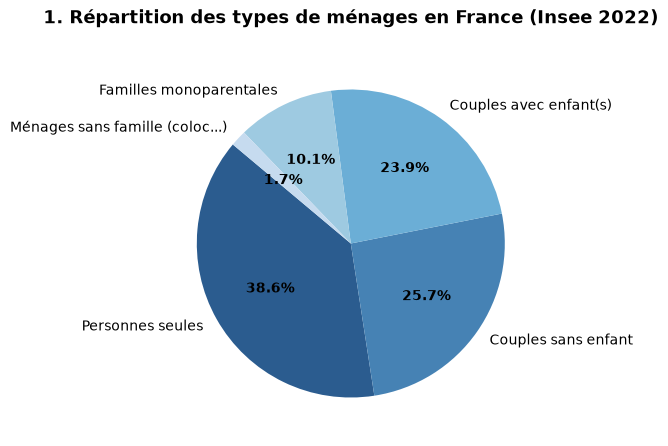

In [24]:
menages_types = {
    'Personnes seules': menages['C22_MENPSEUL'].sum(),
    'Couples sans enfant': menages['C22_MENCOUPSENF'].sum(),
    'Couples avec enfant(s)': menages['C22_MENCOUPAENF'].sum(),
    'Familles monoparentales': menages['C22_MENFAMMONO'].sum(),
    'Ménages sans famille (coloc...)': menages['C22_MENSFAM'].sum()
}
s_men = pd.Series(menages_types)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1', '#c6dbef']
wedges, texts, autotexts = ax.pie(s_men, labels=s_men.index, autopct='%1.1f%%', startangle=140, colors=colors)
for autotext in autotexts:
    autotext.set_weight('bold')

plt.title('1. Répartition des types de ménages en France (Insee 2022)', fontsize=13, fontweight='bold', pad=20)
plt.show()

**Constat** : 38,6 % de personnes seules et 10,1 % de familles monoparentales.

**Apport pour le modèle** : Justifie l'utilisation des ratios de mono-occupants comme indicateurs de tension sur les petites typologies (T1/T2/T3).

### Structure par âge des personnes seules

Series values (in M):
15-24 ans      1.109636
25-54 ans      4.158546
55-79 ans      4.854493
80 ans et +    1.746283
dtype: float64


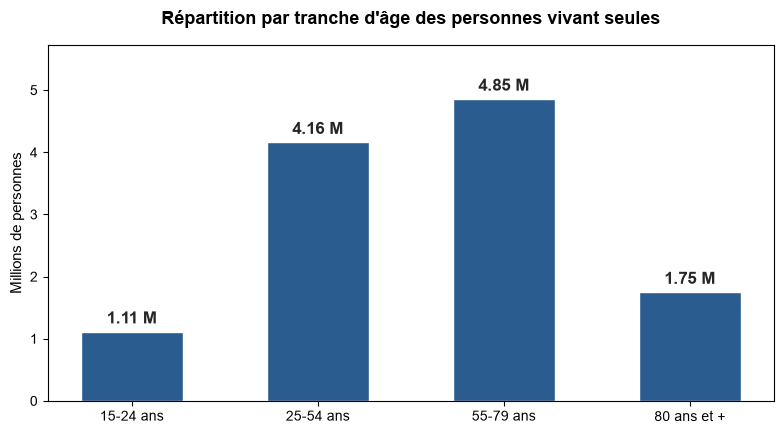

In [31]:
cols_age = {
    '15-24 ans': 'P22_POP1524_PSEUL',
    '25-54 ans': 'P22_POP2554_PSEUL',
    '55-79 ans': 'P22_POP5579_PSEUL',
    '80 ans et +': 'P22_POP80P_PSEUL'
}

values = {}
for label, col in cols_age.items():
    s = pd.to_numeric(menages[col].astype(str).str.replace(',', '.'), errors='coerce')
    values[label] = s.sum() / 1e6 

s_age = pd.Series(values)
print("Series values (in M):")
print(s_age)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

bars = ax.bar(s_age.index, s_age.values, color='#2b5c8f', width=0.55)
ax.set_ylabel('Millions de personnes', fontsize=11)
ax.set_title('Répartition par tranche d\'âge des personnes vivant seules', fontsize=13, fontweight='bold', pad=15)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.08, f'{yval:.2f} M', ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, max(s_age.values) * 1.18)
plt.tight_layout()
plt.show();

**Constat** : Concentration majeure chez les 55-79 ans (4,85 M) et les 25-54 ans (4,16 M).

**Apport pour le modèle** : Permet de distinguer deux segments de demande : l'accession/locatif jeunes actifs d'un côté, et le besoin de logements adaptés au vieillissement de l'autre.

## 6. Création des ratios en vue de l'utilisation du dataset comme grille de lecture structurelle du DVF+

Dans un soucis de simplification du fichier complet des ménages et comme évoqué précédemment, la création de 4 ratios pourra être intéressante à utiliser en lien avec le DVF+, pour rappel :

Taux de personnes seules (C22_MENPSEUL / C22_MEN) : un taux élevé indique un besoin marqué en petites surfaces (T1/T2 ou studios).

Part des familles monoparentales (C22_MENFAMMONO / C22_MEN) et des familles nombreuses (C22_NE24F3 + C22_NE24F4P) : met en évidence la pression sur les logements abordables à typologie moyenne/grande (T3 à T5).

Ratio de décohabitation / Taille moyenne des ménages (C22_PMEN / C22_MEN) : plus le nombre moyen d'habitants par ménage est bas, plus il faut de logements individuels pour une même tranche de population.

Proportion de couples sans enfants (C22_MENCOUPSENF) : signale un profil potentiel d'investisseurs, de primo-accédants seniors ou de retraités cherchant des biens fonctionnels de taille moyenne. 

Ainsi à partir du fichier initial des ménages nous allons générer un nouveau fichier, simplifié.

In [33]:
# Création des ratios dans le fichier
# 1. Taux de personnes seules
menages['taux_personnes_seules'] = np.where(menages['C22_MEN'] > 0, menages['C22_MENPSEUL'] / menages['C22_MEN'], 0)

# 2. Part des familles monoparentales
menages['part_familles_monoparentales'] = np.where(menages['C22_MEN'] > 0, menages['C22_MENFAMMONO'] / menages['C22_MEN'], 0)

# 3. Part des familles nombreuses (3 enfants et +) - par rapport au total des familles C22_FAM ou ménages C22_MEN
# Regardons si C22_FAM ou C22_MEN est plus pertinent
menages['part_familles_nombreuses'] = np.where(menages['C22_MEN'] > 0, (menages['C22_NE24F3'] + menages['C22_NE24F4P']) / menages['C22_MEN'], 0)

# 4. Taille moyenne des ménages (Ratio de décohabitation)
menages['taille_moyenne_menage'] = np.where(menages['C22_MEN'] > 0, menages['C22_PMEN'] / menages['C22_MEN'], 0)

# 5. Part des couples sans enfants
menages['part_couples_sans_enfants'] = np.where(menages['C22_MEN'] > 0, menages['C22_MENCOUPSENF'] / menages['C22_MEN'], 0)


In [34]:
menages.head()

,IRIS,COM,TYP_IRIS,LAB_IRIS,C22_MEN,C22_MENPSEUL,C22_MENHSEUL,C22_MENFSEUL,C22_MENSFAM,C22_MENFAM,...,C22_PMEN1FCOUPUNIQENFCOUP,C22_PMEN1FCOUPENF1ADUL,C22_PMEN1FMONO,C22_FAMTRAD,C22_FAMRECOMP,taux_personnes_seules,part_familles_monoparentales,part_familles_nombreuses,taille_moyenne_menage,part_couples_sans_enfants
0,10010000,1001,Z,5,353.417143,73.628571,44.177143,29.451429,9.817143,269.971429,...,387.777143,88.354286,53.994286,103.080000,24.542857,0.208333,0.069444,0.055556,2.430556,0.333333
1,10020000,1002,Z,5,119.127273,39.709091,29.781818,9.927273,0.000000,79.418182,...,148.909091,0.000000,14.890909,39.709091,0.000000,0.333333,0.041667,0.041667,2.291667,0.291667
2,10040101,1004,H,1,702.787532,289.265076,110.156201,179.108876,9.698603,403.823853,...,823.176441,80.769729,112.626831,211.788398,17.703023,0.411597,0.067829,0.111547,2.315332,0.186520
3,10040102,1004,H,1,1777.324753,789.269399,365.956493,423.312906,19.945500,968.109854,...,1332.099372,132.017808,537.172248,340.022350,28.866303,0.444077,0.110327,0.094771,2.049870,0.226821
4,10040201,1004,H,1,2379.337331,1134.872825,428.121951,706.750874,27.178288,1217.286217,...,1599.412490,196.033145,656.475730,415.956882,52.109027,0.476970,0.107540,0.053906,1.980208,0.209362


In [43]:
# Formatage du code IRIS pour recouper avec le code du DVF+
menages['CODE_IRIS'] = menages['IRIS'].str.zfill(9)

output_cols_insee = [
    'CODE_IRIS',
    'COM',
    'LAB_IRIS',
    'TYP_IRIS',
    'C22_MEN',
    'C22_PMEN',
    'taux_personnes_seules',
    'part_familles_monoparentales',
    'part_familles_nombreuses',
    'taille_moyenne_menage',
    'part_couples_sans_enfants'
]

df_ratios_iris = menages[output_cols_insee]
print("Nombre d'IRIS traités dans INSEE :", len(df_ratios_iris))

Nombre d'IRIS traités dans INSEE : 49276


**Attention** le DVF+ ne possède pas les codes IRIS à proprement parlé mais on peut faire correspondre les données géographiques contenues dans le DVF+ pour faire correspondre à un IRIS, via les contours IRIS fournis par l'INSEE.

In [58]:
cd C:\Users\gabi9\Documents\GITHUB_PROJET_LIORA\projet_compagnon\data\dataset_cible

C:\Users\gabi9\Documents\GITHUB_PROJET_LIORA\projet_compagnon\data\dataset_cible


In [59]:
df_ratios_iris.to_csv('ratios_iris_menages.csv', index=False, encoding='utf-8-sig')